# EDA Competition — sell-in-may 전략 검증

| 순서 | 내용 |
|---|---|
| 01 | **전처리 과정** — EDA에 쓴 데이터를 전처리하는 과정 |
| 02 | **sell-in-may 소개** — 격언의 의미와 예시 |
| 03 | **sell-in-may 검증** — 전략이 맞는지 예시로 검증 |
| 04 | **sell-in-may 기각 요인 파악** — 주가를 움직이는 다른 요인들 |
| 05 | **결론 및 제언** |

> **가설**: sell-in-may 전략이 주가 변동에 유효할 것이다.

## 0. 환경 설정

필요한 패키지 (처음 한 번만, 노트북 셀에서 실행해도 됩니다):

```
pip install pandas numpy matplotlib seaborn yfinance finance-datareader
```

**데이터 파일은 없어도 됩니다.** 아래 CSV는 있으면 쓰고, 없으면 인터넷 데이터로 대신 그립니다.
파일은 노트북과 같은 폴더, `data/` 폴더, 바탕 화면, 다운로드 폴더에서 자동으로 찾습니다.

| 파일 이름 (앞부분만 맞으면 됨) | 없을 때 대신 쓰는 데이터 |
|---|---|
| `코스피_주요주가지수*.csv` (KOSIS) | FinanceDataReader의 KOSPI 지수(`KS11`) 월말 종가 |
| `KRX_상장주식_거래실적*.csv` (KOSIS) | KOSPI + KOSDAQ 일별 거래량의 월 합계 |
| `101_DT_2CBJ3*.csv` (KOSIS 정책금리) | 한국은행 기준금리 변경 이력 (코드에 내장) |
| `원유가격*.csv` (페트로넷 국제유가 월별, 열: `월, 유종, Dubai, Brent, WTI, Oman`) | Brent·WTI 선물(yfinance) 월평균 — Dubai 대신 Brent 사용 |

주가(S&P500, 닛케이, 아마존 등)는 처음 실행할 때 내려받아 `data/cache/`에 저장하고, 다음부터는 저장본을 씁니다.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ── 경로 설정 ─────────────────────────────────────────────
DATA_DIR  = Path('data')            # CSV를 특정 폴더에 두었다면 여기를 바꾸세요. 예: Path(r'C:\Users\사용자이름\Desktop')
CACHE_DIR = Path('data') / 'cache'  # 내려받은 주가 저장 위치

def find_file(*patterns):
    # DATA_DIR, 현재 폴더, data/, 바탕 화면, 다운로드 폴더에서 파일을 찾는다
    # (macOS 한글 자모 분리 이름, '%EC%BD%94' 처럼 인코딩된 이름도 인식)
    import fnmatch, unicodedata
    from urllib.parse import unquote
    norm = lambda x: unicodedata.normalize('NFC', unquote(x))
    home = Path.home()
    folders = [DATA_DIR, Path('.'), Path('data'),
               home / 'Desktop', home / '바탕 화면', home / 'OneDrive' / '바탕 화면',
               home / 'OneDrive' / 'Desktop', home / 'Downloads', home / '다운로드']
    for folder in folders:
        if folder.is_dir():
            files = sorted(p for p in folder.iterdir() if p.is_file())
            for pattern in patterns:
                hits = [p for p in files if fnmatch.fnmatch(norm(p.name), norm(pattern))]
                if hits:
                    print(f'✔ {hits[-1]} 파일을 사용합니다.')
                    return hits[-1]
    print(f'… {patterns[0]} 파일이 없어 대체 데이터를 사용합니다.')
    return None

KOSPI_CSV = find_file('코스피_주요주가지수*.csv')
KRX_CSV   = find_file('KRX_상장주식_거래실적*.csv')
RATE_CSV  = find_file('101_DT_2CBJ3*.csv')
OIL_CSV   = find_file('원유가격*.csv', '*유가*.csv', '*원유*.csv', '*202112*.csv')

# ── 한글 폰트 ─────────────────────────────────────────────
def set_korean_font():
    from matplotlib import font_manager
    installed = {f.name for f in font_manager.fontManager.ttflist}
    candidates = ['NanumGothic', 'Malgun Gothic', 'AppleGothic', 'Noto Sans CJK KR', 'Noto Sans KR']
    for name in candidates:
        if name in installed:
            plt.rcParams['font.family'] = name
            break
    plt.rcParams['axes.unicode_minus'] = False   # 마이너스 기호 깨짐 방지

set_korean_font()

# ── 공통 함수 ─────────────────────────────────────────────
def to_num(s):
    # '1,234' 같은 문자열도 숫자로 변환
    return pd.to_numeric(s.astype(str).str.replace(',', ''), errors='coerce')

def month_cols(columns, year=None):
    # '2019.01' 같은 월별 열만 고른다 ('2008' 같은 연간 열은 제외)
    import re
    cols = [c for c in columns if re.fullmatch(r'\d{4}\.\d{2}( 월)?', str(c).strip())]
    return [c for c in cols if year is None or str(c).startswith(str(year))]

def read_csv_any(path, **kw):
    # KOSIS CSV는 utf-8 / cp949 중 하나라서 둘 다 시도
    for enc in ('utf-8-sig', 'cp949'):
        try:
            return pd.read_csv(path, encoding=enc, **kw)
        except UnicodeDecodeError:
            pass
    raise ValueError(f'{path} 인코딩을 읽을 수 없습니다.')

def get_prices(ticker, start, end, source='yf'):
    # 일별 OHLCV를 받아 캐시에 저장 (source: 'yf' = yfinance, 'fdr' = FinanceDataReader)
    cache = CACHE_DIR / f"{source}_{ticker.replace('^', '').replace('=', '')}_{start}_{end}.csv"
    if cache.exists():
        return pd.read_csv(cache, index_col=0, parse_dates=True)
    if source == 'yf':
        import yfinance as yf
        df = yf.download(ticker, start=start, end=end, auto_adjust=True, progress=False)
        if isinstance(df.columns, pd.MultiIndex):
            df.columns = df.columns.get_level_values(0)
    else:
        import FinanceDataReader as fdr
        df = fdr.DataReader(ticker, start, end)
    if df is None or len(df) == 0:
        raise RuntimeError(f'{ticker} 데이터를 받지 못했습니다. 인터넷 연결과 yfinance / finance-datareader 설치를 확인하세요.')
    df = df[[c for c in ['Open', 'High', 'Low', 'Close', 'Volume'] if c in df.columns]]
    CACHE_DIR.mkdir(parents=True, exist_ok=True)
    df.to_csv(cache)
    return df

def monthly(series, how='last'):
    # 일별 → 월별 (월말 종가 'last' / 월 합계 'sum' / 월 평균 'mean'), 인덱스는 해당 월 1일
    out = getattr(series.groupby(series.index.to_period('M')), how)()
    out.index = out.index.to_timestamp()
    return out

✔ data/코스피_주요주가지수_20261113232101.csv 파일을 사용합니다.
✔ data/KRX_상장주식_거래실적_20261113232200.csv 파일을 사용합니다.
… 101_DT_2CBJ3*.csv 파일이 없어 대체 데이터를 사용합니다.
✔ data/원유가격_2020_2021.csv 파일을 사용합니다.


## 1. 전처리 과정
### 1-1. 코스피 지수 (2008.01 ~ 2009.04)

In [2]:
if KOSPI_CSV is not None:
    #데이터불러오기
    data = read_csv_any(KOSPI_CSV)
    display(data)
    df = to_num(data.loc[0, month_cols(data.columns)])   # 0행 = KOSPI, 월별 열만 (연간 열 제외)
else:
    # 대체: KOSPI 지수 월말 종가
    kospi_d = get_prices('KS11', '2008-01-01', '2009-04-30', source='fdr')
    df = monthly(kospi_d['Close'])
    df.index = df.index.strftime('%Y.%m')
df

,지수종류별(1),지수종류별(2),2008.01,2008.02,2008.03,2008.04,2008.05,2008.06,2008.07,2008.08,2008.09,2008.10,2008.11,2008.12,2009.01,2009.02,2009.03,2009.04,2008,2009
0,KOSPI,소계,1624.68,1711.62,1703.99,1825.47,1852.02,1674.92,1594.67,1474.24,1448.06,1113.06,1076.07,1124.47,1162.11,1063.03,1206.26,1369.36,1124.47,1682.77
1,KOSPI 200,소계,207.77,216.85,217.65,235.00,237.46,213.52,204.12,188.96,186.62,147.50,140.66,146.35,151.33,138.07,157.01,176.00,146.35,221.86
2,V-KOSPI 200,소계,31.39,29.21,27.05,22.04,23.06,25.15,23.82,25.66,36.78,81.27,57.79,48.61,48.21,47.36,39.56,34.57,48.61,20.35
3,KOSPI 100,소계,1532.82,1589.24,1595.55,1727.82,1748.17,1574.24,1505.80,1397.89,1381.29,1100.37,1045.12,1084.76,1122.58,1022.18,1160.76,1297.06,1084.76,1659.25
4,KOSPI 50,소계,1382.74,1416.32,1426.65,1549.27,1574.99,1409.51,1342.53,1248.79,1235.46,1002.38,942.33,970.04,1004.79,915.50,1038.21,1145.63,970.04,1470.01
5,시가총액규모별,대형주,1577.27,1644.04,1657.05,1780.91,1804.90,1614.75,1544.56,1427.30,1408.04,1099.69,1051.02,1094.56,1134.61,1026.00,1163.37,1304.79,1094.56,1643.82
6,시가총액규모별,중형주,2069.13,2279.39,2142.36,2271.29,2305.92,2214.43,2044.65,1888.34,1810.38,1236.95,1289.29,1397.04,1398.28,1357.18,1537.05,1861.31,1397.04,1986.60
7,시가총액규모별,소형주,1207.73,1308.68,1245.07,1273.06,1323.19,1284.73,1191.26,1079.12,1003.16,710.26,709.85,754.07,789.10,785.05,895.77,1101.75,754.07,1161.95
8,F-KOSPI 200,소계,1076.35,1122.94,1121.11,1221.06,1222.87,1099.31,1048.68,967.11,936.31,740.18,706.45,744.27,768.59,694.11,798.32,891.93,744.27,1129.30
9,F-KOSPI 200 인버스지수,소계,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1039.02


2008.01    1624.68
2008.02    1711.62
2008.03    1703.99
2008.04    1825.47
2008.05    1852.02
2008.06    1674.92
2008.07    1594.67
2008.08    1474.24
2008.09    1448.06
2008.10    1113.06
2008.11    1076.07
2008.12    1124.47
2009.01    1162.11
2009.02    1063.03
2009.03    1206.26
2009.04    1369.36
Name: 0, dtype: float64

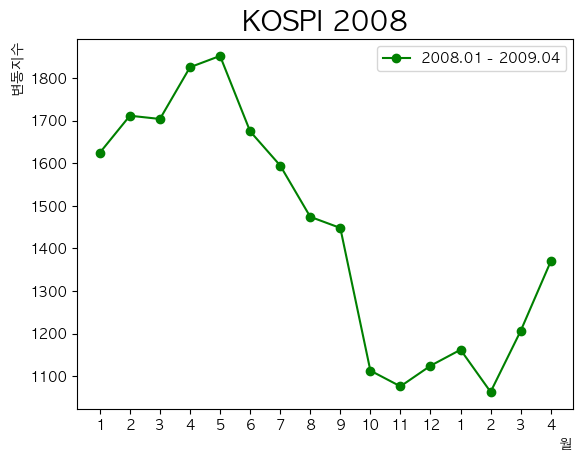

In [3]:
plt.plot(df.values, marker = 'o', color = 'g', label = '2008.01 - 2009.04')

plt.title('KOSPI 2008',fontdict={'size':20})
plt.xlabel('월', loc = 'right')
plt.ylabel('변동지수', loc = 'top')
plt.xticks(ticks = [i for i in range(0,16)], labels = [i for i in range(1,13)] + [1,2,3,4])
plt.legend(loc = 'upper right')
plt.show()

### 1-2. KRX 상장주식 거래실적 (2019 ~ 2023)

,거래구분별(1),거래구분별(2),거래구분별(3),2019.01,2019.02,2019.03,2019.04,2019.05,2019.06,2019.07,...,2023.03,2023.04,2023.05,2023.06,2023.07,2023.08,2023.09,2023.10,2023.11,2023.12
0,매매일수 (일),소계,소계,22,17,20,22,21,19,23,...,22,20,20,21,21,22,19,19,22,19
1,거래량,합계,거래량 (천주),24481262,20620284,22039093,28251771,28517389,27518381,30048260,...,36390971,48546613,39248643,36654582,32828451,38038401,27803750,26667899,27965267,28394849
2,거래량,합계,일평균 (천주),1112785,1212958,1101955,1284171,1357971,1448336,1306446,...,1654135,2427331,1962432,1745456,1563260,1729018,1463355,1403574,1271149,1494466
3,거래량,최대,거래량 (천주),1338892,1526780,1304819,1548709,1768841,2011930,1823116,...,2131954,3277146,2488596,2026120,2071698,2070424,1662173,1838824,1496070,1725063
4,거래량,최대,월 (월),1,2,3,4,5,6,7,...,3,4,5,6,7,8,9,10,11,12
5,거래량,최대,일 (일),17,28,19,16,14,20,24,...,30,20,12,20,26,11,7,16,29,21
6,거래량,최소,거래량 (천주),866237,1049129,958060,968469,1081651,997420,977806,...,1418462,1936013,1687136,1511669,1147131,1418732,1211210,1066437,1101190,1187668
7,거래량,최소,월 (월),1,2,3,4,5,6,7,...,3,4,5,6,7,8,9,10,11,12
8,거래량,최소,일 (일),2,18,26,1,31,5,22,...,21,28,22,30,31,1,27,6,24,18
9,거래대금,합계,거래대금 (백만원),205457227,163313220,187819871,211889424,204031778,169145402,197701185,...,476860419,528197742,360912349,401668531,567451171,504906511,362540828,284432067,348023889,358422767


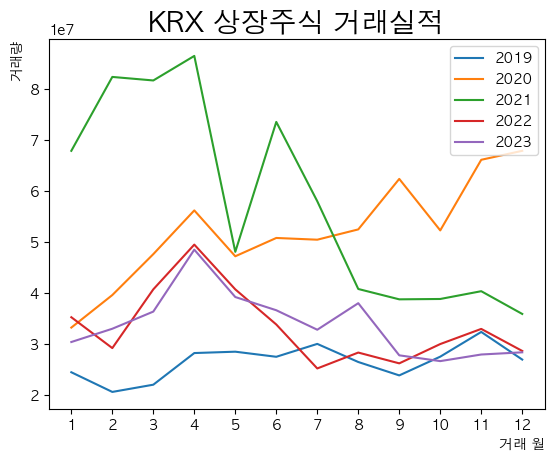

In [4]:
if KRX_CSV is not None:
    #데이터 불러오기
    data = read_csv_any(KRX_CSV)
    display(data)

    #년도별로 컬럼 묶음
    c1 = month_cols(data.columns, 2019)
    c2 = month_cols(data.columns, 2020)
    c3 = month_cols(data.columns, 2021)
    c4 = month_cols(data.columns, 2022)
    c5 = month_cols(data.columns, 2023)

    #년도별 거래량 합계 변수에 저장 (1행 = 거래량 합계)
    d1 = to_num(data.loc[1, c1])
    d2 = to_num(data.loc[1, c2])
    d3 = to_num(data.loc[1, c3])
    d4 = to_num(data.loc[1, c4])
    d5 = to_num(data.loc[1, c5])
else:
    # 대체: KOSPI + KOSDAQ 일별 거래량을 월별로 합산
    ks = get_prices('KS11', '2019-01-01', '2023-12-31', source='fdr')['Volume']
    kq = get_prices('KQ11', '2019-01-01', '2023-12-31', source='fdr')['Volume']
    vol = monthly(ks.add(kq, fill_value=0), 'sum')
    d1, d2, d3, d4, d5 = [vol.loc[str(y)] for y in range(2019, 2024)]

def plot_krx():
    #lineplot으로 나타내기
    plt.plot(d1.values, label = '2019')
    plt.plot(d2.values, label = '2020')
    plt.plot(d3.values, label = '2021')
    plt.plot(d4.values, label = '2022')
    plt.plot(d5.values, label = '2023')

    plt.title('KRX 상장주식 거래실적',fontdict={'size':20})
    plt.xlabel('거래 월', loc = 'right')
    plt.ylabel('거래량', loc = 'top')
    plt.xticks(ticks = [0,1,2,3,4,5,6,7,8,9,10,11], labels = [i for i in range(1,13)])
    plt.legend(loc = 'upper right')
    plt.show()

plot_krx()

### 1-3. 중앙은행 정책금리 (대한민국, 2019 ~ 2023)

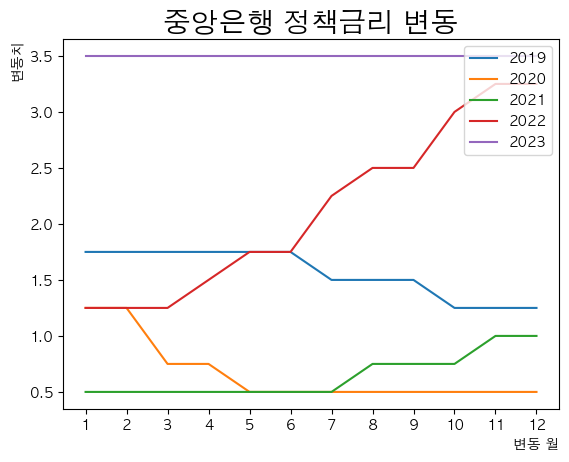

In [5]:
if RATE_CSV is not None:
    #데이터 불러오기
    inp = read_csv_any(RATE_CSV)

    #대한민국 금리 데이터만 뽑기, 항목으로 인덱스 설정
    inp1 = inp[inp['국가별']=='대한민국']
    inp1 = inp1.set_index('항목')

    #결측값 확인
    print(inp1.isnull().sum().unique())

    #필요없는 행 제거
    inp1 = inp1.drop(columns=['단위','국가별','Unnamed: 75'], errors='ignore')
    display(inp1)

    #년도별로 컬럼 묶음
    i1 = month_cols(inp.columns, 2019)
    i2 = month_cols(inp.columns, 2020)
    i3 = month_cols(inp.columns, 2021)
    i4 = month_cols(inp.columns, 2022)
    i5 = month_cols(inp.columns, 2023)

    #년도별 정책금리 변수에 저장
    df1 = to_num(inp1.loc['중앙은행 정책 금리', i1])
    df2 = to_num(inp1.loc['중앙은행 정책 금리', i2])
    df3 = to_num(inp1.loc['중앙은행 정책 금리', i3])
    df4 = to_num(inp1.loc['중앙은행 정책 금리', i4])
    df5 = to_num(inp1.loc['중앙은행 정책 금리', i5])
else:
    # 대체: 한국은행 기준금리 변경 이력 (변경일, 금리%) → 월말 기준 월별 금리
    changes = [('2018-11-30', 1.75), ('2019-07-18', 1.50), ('2019-10-16', 1.25),
               ('2020-03-16', 0.75), ('2020-05-28', 0.50), ('2021-08-26', 0.75),
               ('2021-11-25', 1.00), ('2022-01-14', 1.25), ('2022-04-14', 1.50),
               ('2022-05-26', 1.75), ('2022-07-13', 2.25), ('2022-08-25', 2.50),
               ('2022-10-12', 3.00), ('2022-11-24', 3.25), ('2023-01-13', 3.50)]
    rate = pd.Series([r for _, r in changes], index=pd.to_datetime([d for d, _ in changes]))
    month_ends = pd.date_range('2019-01-31', '2023-12-31', freq=pd.offsets.BMonthEnd())
    rate_m = rate.reindex(rate.index.union(month_ends)).ffill().loc[month_ends]
    df1, df2, df3, df4, df5 = [rate_m.loc[str(y)] for y in range(2019, 2024)]

def plot_rate():
    #lineplot으로 나타내기
    plt.plot(df1.values, label = '2019')
    plt.plot(df2.values, label = '2020')
    plt.plot(df3.values, label = '2021')
    plt.plot(df4.values, label = '2022')
    plt.plot(df5.values, label = '2023')

    plt.title('중앙은행 정책금리 변동',fontdict={'size':20})
    plt.xlabel('변동 월', loc = 'right')
    plt.ylabel('변동치', loc = 'top')
    plt.xticks(ticks = [0,1,2,3,4,5,6,7,8,9,10,11], labels = [i for i in range(1,13)])
    plt.legend(loc = 'upper right')
    plt.show()

plot_rate()

### 1-4. 2020~21년 KRX 거래량과 금리 비교

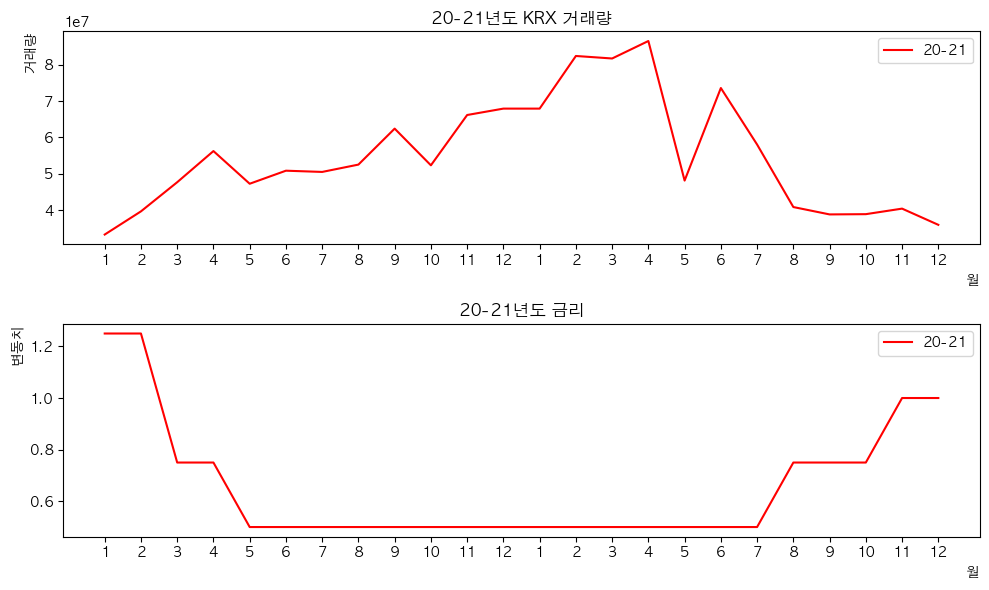

In [6]:
# 20년도와 21년 krx 거래량과 금리변동데이터 비교해보기
nd = np.concatenate((d2.values, d3.values),axis=0) #20~21년도 krx 거래량
ni = np.concatenate((df2.values, df3.values),axis=0) #20~21년도 금리변동

def plot_krx_vs_rate():
    #subplot으로 krx, 금리 데이터 각각 한번에 나타냄
    plt.figure(figsize=(10, 6))
    plt.subplot(2, 1, 1)
    plt.plot(nd, color = 'r', label = '20-21')
    plt.xlabel('월', loc = 'right')
    plt.ylabel('거래량', loc = 'top')
    plt.xticks(ticks = [i for i in range(0,24)], labels = [i for i in range(1,13)]*2)
    plt.legend(loc = 'upper right')
    plt.title('20-21년도 KRX 거래량')

    plt.subplot(2, 1, 2)
    plt.plot(ni, color = 'r', label = '20-21')
    plt.xlabel('월', loc = 'right')
    plt.ylabel('변동치', loc = 'top')
    plt.xticks(ticks = [i for i in range(0,24)], labels = [i for i in range(1,13)]*2)
    plt.legend(loc = 'upper right')
    plt.title('20-21년도 금리')

    plt.tight_layout()
    plt.show()

plot_krx_vs_rate()

## 2. sell-in-may 소개

> **sell-in-may란?** "5월에 매도하고 떠나라(Sell in May and go away)."
> 11월부터 4월까지의 기간이 다른 달보다 평균적으로 주식 시장 성장이 훨씬 더 높다는 이론에 기초한 주식 투자 전략.

아래 네 그래프는 5월 이후 주가·거래가 약해지는 모습이 나타난 사례입니다.

### 2-1. 2008년 코스피 주가 (1-1 그래프 재사용)

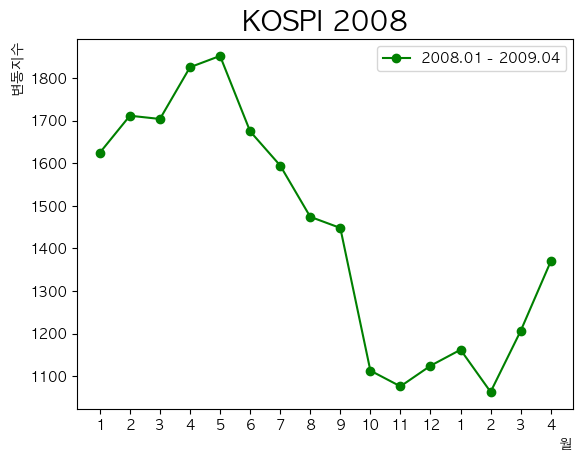

In [7]:
plt.plot(df.values, marker = 'o', color = 'g', label = '2008.01 - 2009.04')
plt.title('KOSPI 2008',fontdict={'size':20})
plt.xlabel('월', loc = 'right')
plt.ylabel('변동지수', loc = 'top')
plt.xticks(ticks = [i for i in range(0,16)], labels = [i for i in range(1,13)] + [1,2,3,4])
plt.legend(loc = 'upper right')
plt.show()

### 2-2. 2011년 S&P500 월별 수익률

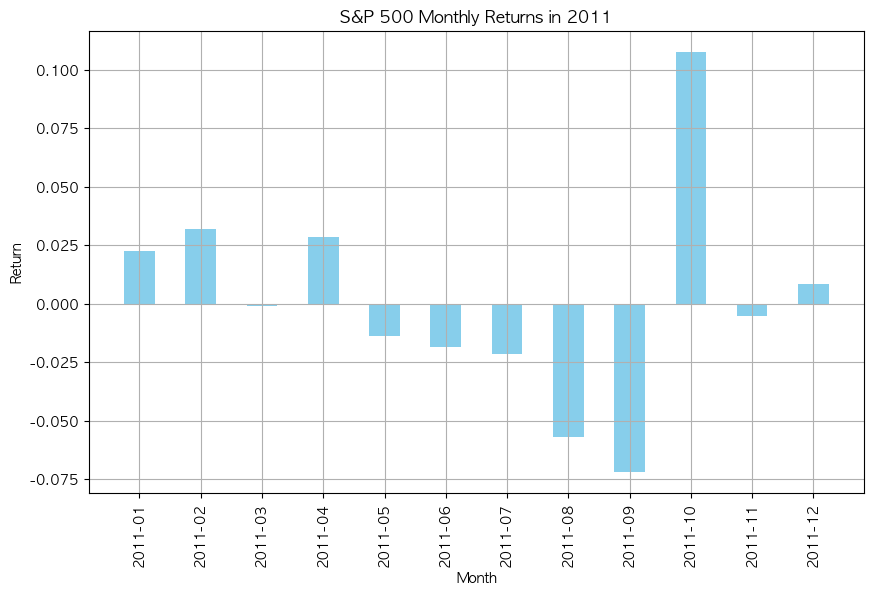

In [8]:
spx = get_prices('^GSPC', '2010-12-01', '2012-01-01')
spx_m = monthly(spx['Close']).pct_change().loc['2011']

plt.figure(figsize=(10, 6))
plt.bar(spx_m.index.strftime('%Y-%m'), spx_m.values, color='skyblue', width=0.5)
plt.xticks(rotation=90)
plt.title('S&P 500 Monthly Returns in 2011')
plt.xlabel('Month')
plt.ylabel('Return')
plt.grid(True)
plt.show()

### 2-3. 2021년 삼성전자 주가 추이 (4월 ~ 12월)

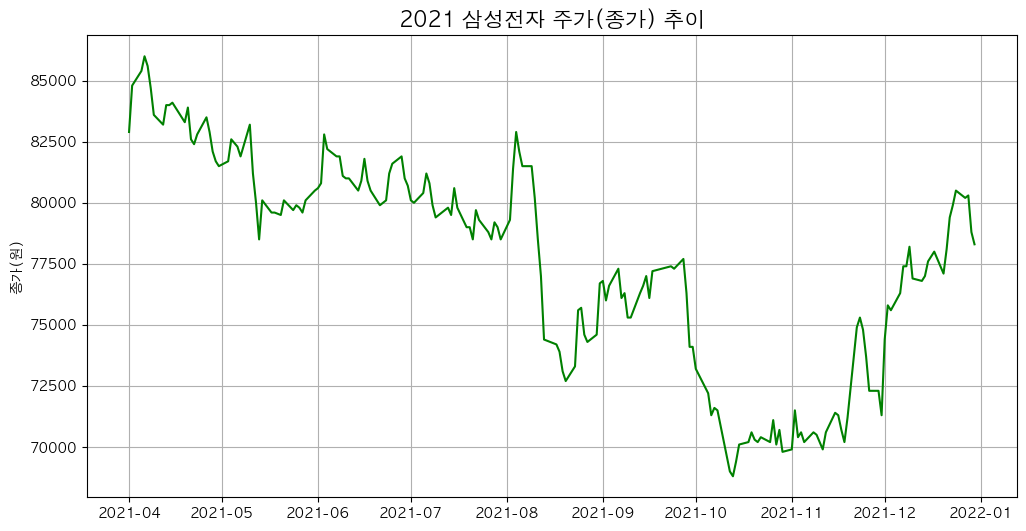

In [9]:
sam = get_prices('005930', '2021-04-01', '2021-12-31', source='fdr')

plt.figure(figsize=(12, 6))
plt.plot(sam.index, sam['Close'], color='g')
plt.title('2021 삼성전자 주가(종가) 추이', fontdict={'size':15})
plt.ylabel('종가(원)')
plt.grid(True)
plt.show()

### 2-4. 2022년 아모레퍼시픽 월별 거래량

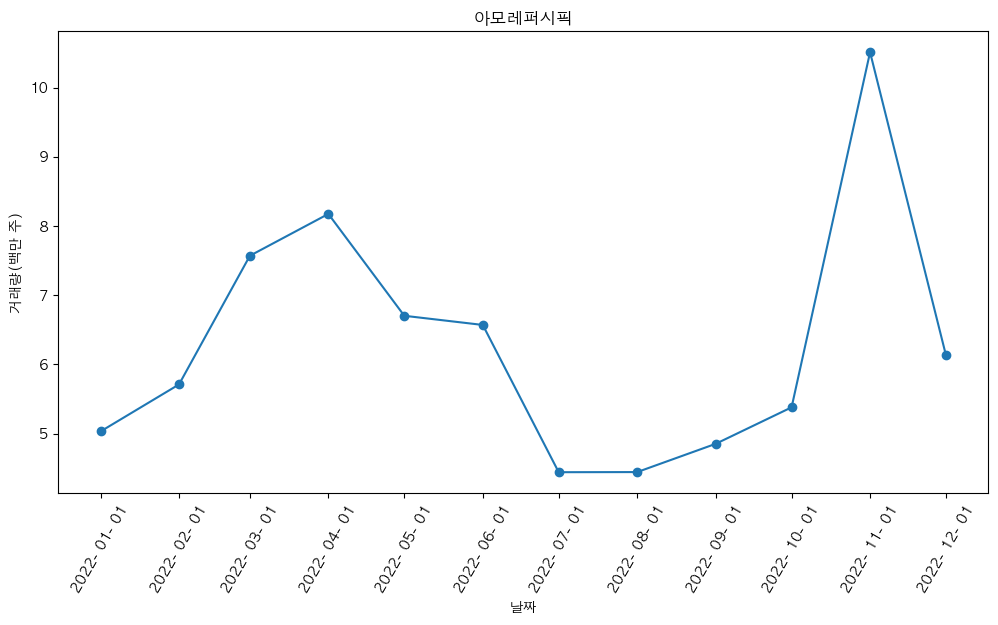

In [10]:
amore = get_prices('090430', '2022-01-01', '2022-12-31', source='fdr')
amore_vol = monthly(amore['Volume'], 'sum') / 1e6     # 백만 주

plt.figure(figsize=(12, 6))
plt.plot(amore_vol.index, amore_vol.values, marker='o')
plt.title('아모레퍼시픽')
plt.xlabel('날짜')
plt.ylabel('거래량(백만 주)')
plt.xticks(amore_vol.index, amore_vol.index.strftime('%Y- %m- %d'), rotation=60)
plt.show()

## 3. sell-in-may 검증

> **하지만! sell-in-may 전략이 매년 통할까?**
> 다른 주가 및 지수들을 통해 오히려 매년 다른 것을 확인할 수 있었다. ex) KRX 상장주식 거래실적

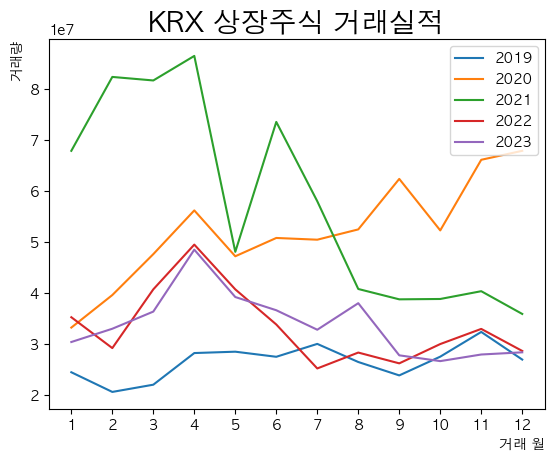

In [11]:
plot_krx()

### (추가) 연도별 정량 확인 — KOSPI 반기 수익률

그래프 인상만으로는 판단이 어려우므로, 연도별로 **11월~4월(보유 기간)** 수익률과 **5월~10월(매도 기간)** 수익률을 직접 비교합니다.
sell-in-may가 맞다면 매년 파란 막대(11~4월)가 주황 막대(5~10월)보다 높아야 합니다.

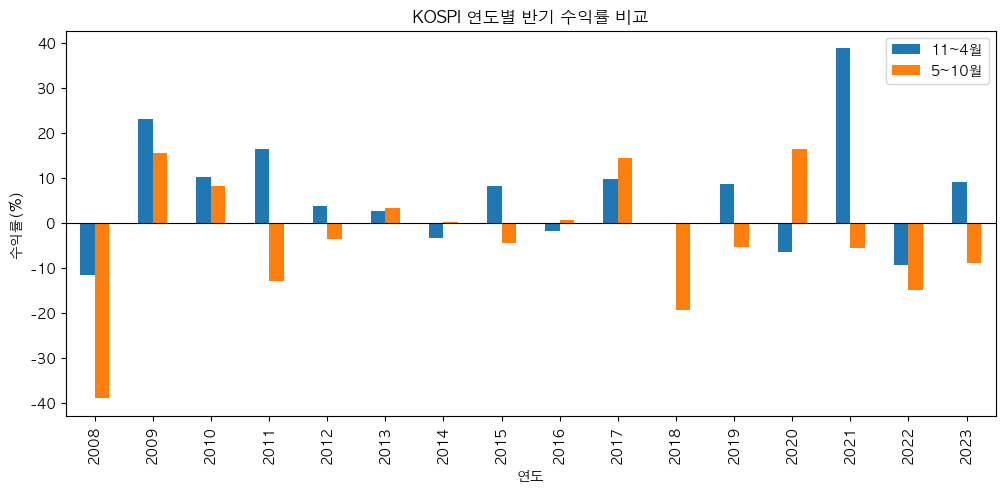

성립한 해: 11 / 16년


,11~4월,5~10월,sell-in-may 성립
연도,,,
2008,-11.59,-39.03,True
2009,23.03,15.43,True
2010,10.18,8.12,True
2011,16.43,-12.92,True
2012,3.82,-3.53,True
2013,2.71,3.37,False
2014,-3.36,0.13,False
2015,8.28,-4.59,True
2016,-1.74,0.70,False


In [12]:
kospi = get_prices('KS11', '2007-10-01', '2024-01-01', source='fdr')
km = monthly(kospi['Close'])                    # 월말 종가

rows = []
for y in range(2008, 2024):
    winter = km[f'{y}-04-01'] / km[f'{y-1}-10-01'] - 1   # 전년 10월말 → 4월말 (11~4월 보유)
    summer = km[f'{y}-10-01'] / km[f'{y}-04-01'] - 1     # 4월말 → 10월말 (5~10월 보유)
    rows.append({'연도': y, '11~4월': winter * 100, '5~10월': summer * 100})
season = pd.DataFrame(rows).set_index('연도')
season['sell-in-may 성립'] = season['11~4월'] > season['5~10월']

season.plot(kind='bar', y=['11~4월', '5~10월'], figsize=(12, 5))
plt.axhline(0, color='black', lw=0.8)
plt.title('KOSPI 연도별 반기 수익률 비교')
plt.ylabel('수익률(%)')
plt.show()

print(f"성립한 해: {season['sell-in-may 성립'].sum()} / {len(season)}년")
season.round(2)

**검증 흐름**

1. sell-in-may 전략을 검증하기 위해 여러 데이터 확인
2. 주식은 sell-in-may 전략보다 다양한 요인에 영향을 더 크게 받음
3. sell-in-may 전략은 유효성이 떨어짐
4. **가설 기각**

> 그렇다면 sell-in-may 전략이 통하지 않는 요인들은 무엇이 있을까?

## 4. sell-in-may 기각 요인

### 4-1. 정치적 요인 — 미국 대선
바이든 후보가 2020년 8월 친환경 에너지를 공약으로 내세운 뒤 친환경 에너지 관련주가 상승했습니다.
(관련주 대표로 iShares Global Clean Energy ETF `ICLN`을 사용합니다. 발표 때 쓴 종목이 따로 있다면 `ticker`만 바꾸세요.)

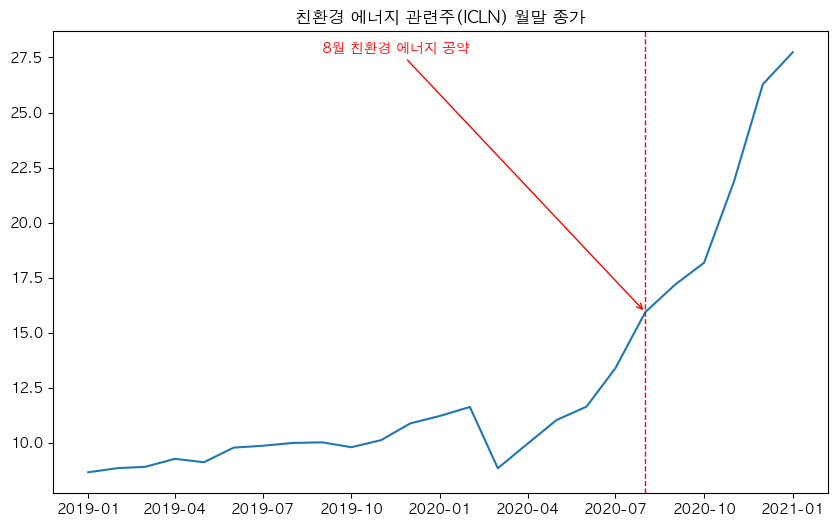

In [13]:
ticker = 'ICLN'
green = monthly(get_prices(ticker, '2019-01-01', '2021-02-01')['Close'])

plt.figure(figsize=(10, 6))
plt.plot(green.index, green.values)
plt.axvline(pd.Timestamp('2020-08-01'), color='r', ls='--', lw=1)
plt.annotate('8월 친환경 에너지 공약', xy=(pd.Timestamp('2020-08-01'), green['2020-08-01']),
             xytext=(pd.Timestamp('2019-09-01'), green.max()), color='r',
             arrowprops=dict(arrowstyle='->', color='r'))
plt.title(f'친환경 에너지 관련주({ticker}) 월말 종가')
plt.show()

### 4-2. 자연재해적 요인 — 동일본 대지진·쓰나미
2011년 3월 일본에 큰 쓰나미가 강타한 전후로 닛케이225 지수가 완전히 달라졌습니다. (비교: 평범한 해인 2009년)

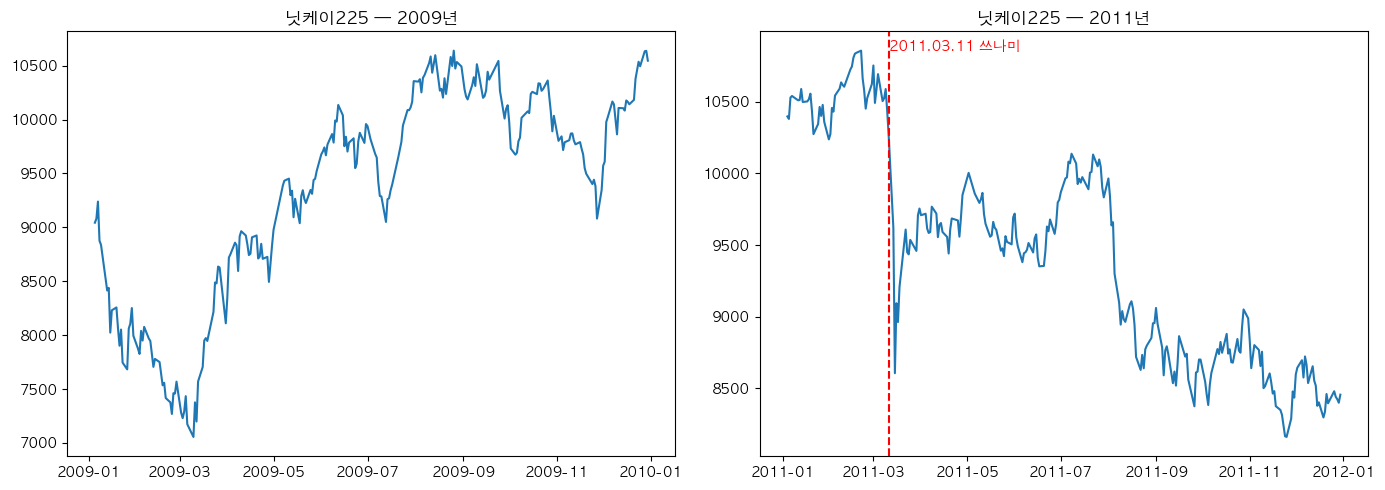

In [14]:
nk09 = get_prices('^N225', '2009-01-01', '2010-01-01')
nk11 = get_prices('^N225', '2011-01-01', '2012-01-01')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(nk09.index, nk09['Close'])
axes[0].set_title('닛케이225 — 2009년')
axes[1].plot(nk11.index, nk11['Close'])
axes[1].axvline(pd.Timestamp('2011-03-11'), color='r', ls='--')
axes[1].annotate('2011.03.11 쓰나미', xy=(pd.Timestamp('2011-03-11'), nk11['Close'].max()), color='r')
axes[1].set_title('닛케이225 — 2011년')
plt.tight_layout()
plt.show()

### 4-3. 경제적 요인 — 항공사 인수합병 발표
2020년 11월 대한항공의 아시아나항공 인수합병 발표로 대한항공 거래량이 급등했습니다.

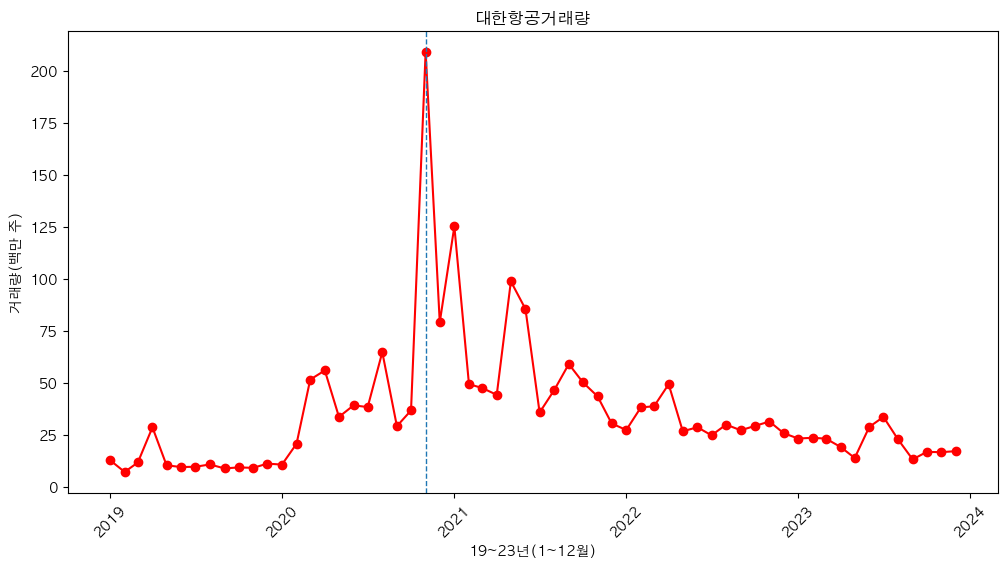

In [15]:
kal = get_prices('003490', '2019-01-01', '2023-12-31', source='fdr')
kal_vol = monthly(kal['Volume'], 'sum') / 1e6   # 백만 주

plt.figure(figsize=(12, 6))
plt.plot(kal_vol.index, kal_vol.values, color='r', marker='o')
plt.axvline(pd.Timestamp('2020-11-01'), color='tab:blue', ls='--', lw=1)
plt.title('대한항공거래량')
plt.xlabel('19~23년(1~12월)')
plt.ylabel('거래량(백만 주)')
plt.xticks(rotation=45)
plt.show()

### 4-4. 특수적 요인 — 코로나19
코로나로 인해 비대면 수요가 늘며 아마존 주가가 2020년 이후 꾸준히 올랐습니다.

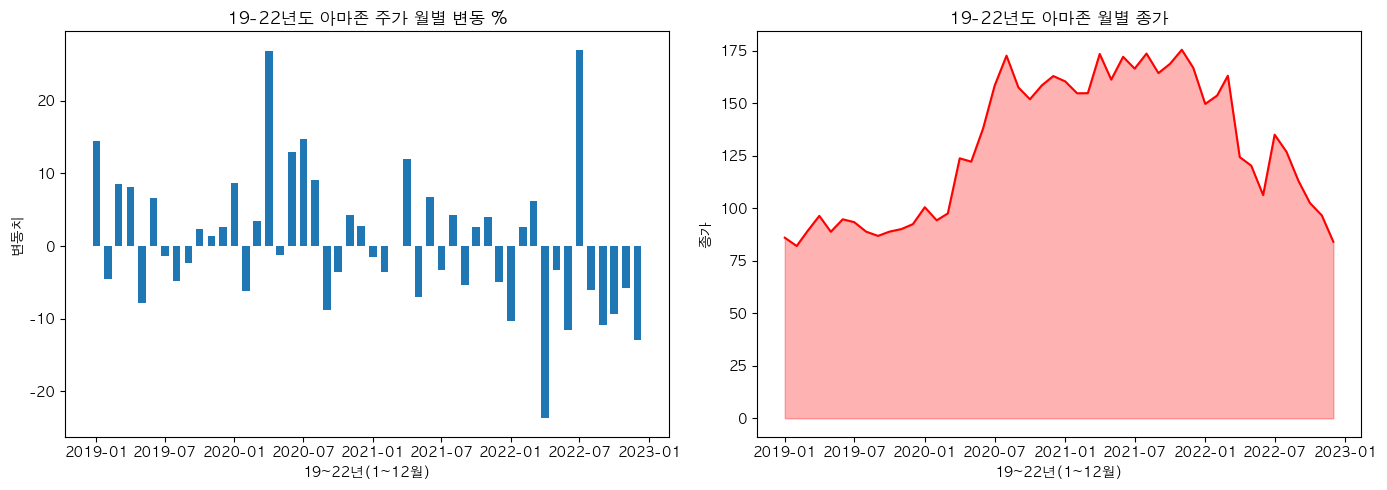

In [16]:
amzn = monthly(get_prices('AMZN', '2018-12-01', '2023-01-01')['Close'])
amzn_chg = amzn.pct_change().loc['2019':'2022'] * 100
amzn = amzn.loc['2019':'2022']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].bar(amzn_chg.index, amzn_chg.values, width=20)
axes[0].set_title('19-22년도 아마존 주가 월별 변동 %')
axes[0].set_xlabel('19~22년(1~12월)')
axes[0].set_ylabel('변동치')

axes[1].plot(amzn.index, amzn.values, color='r')
axes[1].fill_between(amzn.index, amzn.values, color='r', alpha=0.3)
axes[1].set_title('19-22년도 아마존 월별 종가')
axes[1].set_xlabel('19~22년(1~12월)')
axes[1].set_ylabel('종가')
plt.tight_layout()
plt.show()

### 4-5. 거시경제적 요인 — 금리
금리 하락으로 인해 주식 거래량이 상승했습니다. (1-3, 1-4 그래프)

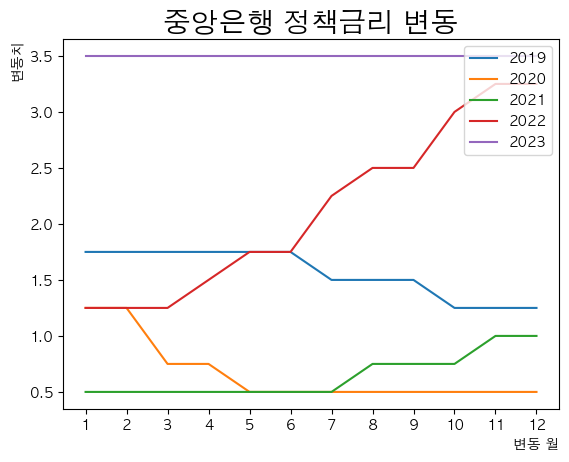

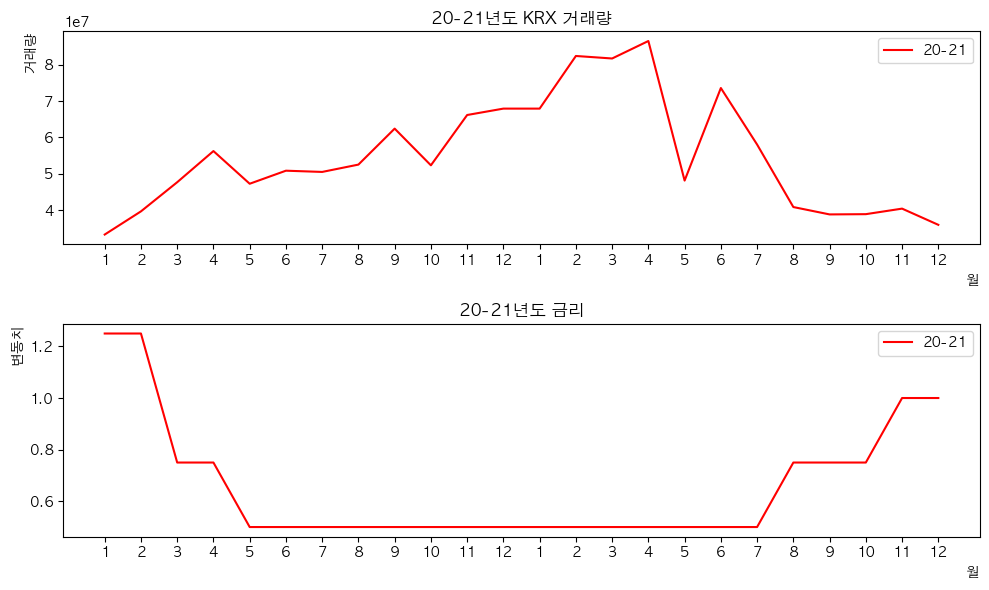

In [17]:
plot_rate()
plot_krx_vs_rate()

## 5. 복합적 요인 파악

### 5-1. 코로나 백신 개발로 인한 항공업 주가 상승
2020년 7월 옥스퍼드 백신 면역 반응 성공 소식 이후 델타항공 주가가 반등했습니다.

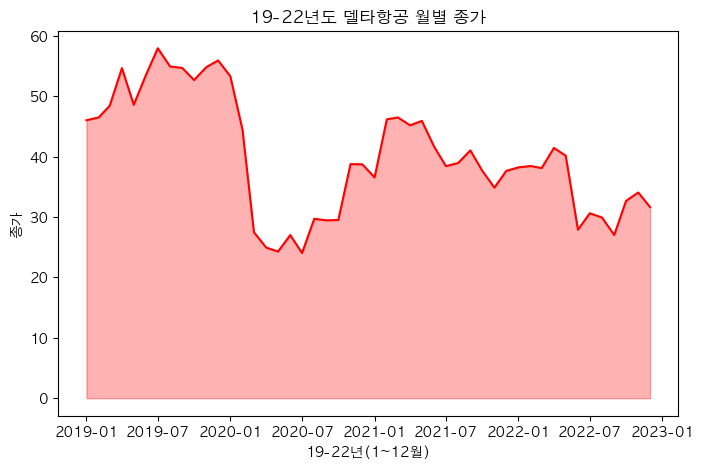

In [18]:
dal = monthly(get_prices('DAL', '2019-01-01', '2023-01-01')['Close'])
xom = monthly(get_prices('XOM', '2019-01-01', '2023-01-01')['Close'])

def area_plot(ax, s, title):
    ax.plot(s.index, s.values, color='r')
    ax.fill_between(s.index, s.values, color='r', alpha=0.3)
    ax.set_title(title)
    ax.set_xlabel('19-22년(1~12월)')
    ax.set_ylabel('종가')

fig, ax = plt.subplots(figsize=(8, 5))
area_plot(ax, dal, '19-22년도 델타항공 월별 종가')
plt.show()

### 5-2. 원유 가격 하락으로 인한 항공사 주가 상승
세계 3대 유종(Dubai, Brent, WTI)의 2020~21년 월별 가격.
`OIL_CSV`가 없으면 Brent·WTI를 선물 가격(yfinance)으로 대신 받고, 이후 분석의 기준 유종을 Brent로 바꿉니다.

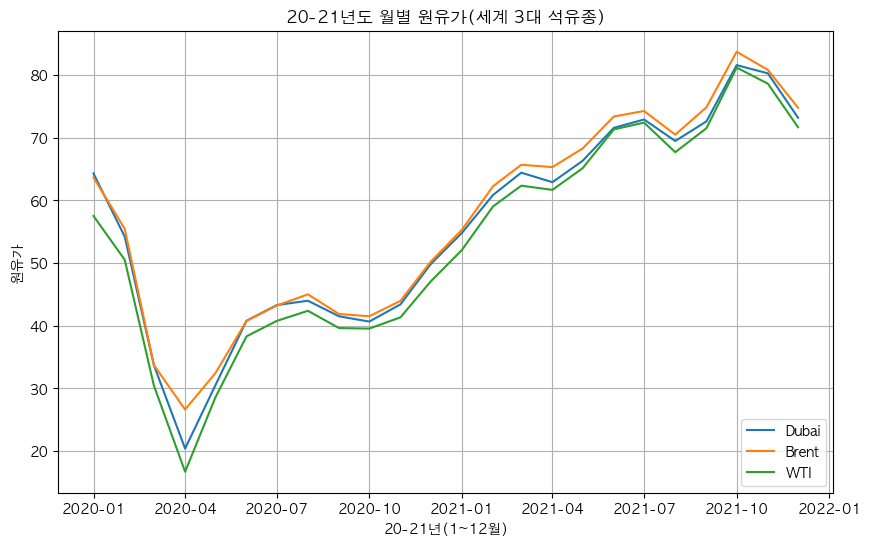

In [19]:
if OIL_CSV is not None:
    raw = read_csv_any(OIL_CSV, dtype=str)
    # 페트로넷 형식: '20년 01월', '02월', ... (연도는 1월에만 표시) + 맨 아래 전월비/평균 행
    import re
    dates, year = [], None
    for v in raw.iloc[:, 0].astype(str):
        m = re.match(r'\s*(?:(\d{2,4})년\s*)?(\d{1,2})월', v)
        if m and (m.group(1) or year):
            year = int(m.group(1)) if m.group(1) else year
            dates.append(pd.Timestamp(year + 2000 if year < 100 else year, int(m.group(2)), 1))
        else:
            dates.append(pd.NaT)                     # 요약 행(전월비, 평균 등)은 버림
    oil = raw.assign(기간=dates).dropna(subset=['기간']).set_index('기간')
    oil = oil[['Dubai', 'Brent', 'WTI']].apply(to_num)
    BASE = 'Dubai'
else:
    print('⚠ OIL_CSV가 없어 Brent(BZ=F)·WTI(CL=F) 선물 월평균으로 대체합니다. Dubai 분석은 Brent로 대신합니다.')
    oil = pd.DataFrame({
        'Brent': monthly(get_prices('BZ=F', '2020-01-01', '2022-01-01')['Close'], 'mean'),
        'WTI':   monthly(get_prices('CL=F', '2020-01-01', '2022-01-01')['Close'], 'mean'),
    })
    BASE = 'Brent'
oil = oil.loc['2020':'2021']

plt.figure(figsize=(10, 6))
for col in oil.columns:
    plt.plot(oil.index, oil[col], label=col)
plt.title('20-21년도 월별 원유가(세계 3대 석유종)')
plt.xlabel('20-21년(1~12월)')
plt.ylabel('원유가')
plt.grid(True)
plt.legend(loc='lower right')
plt.show()

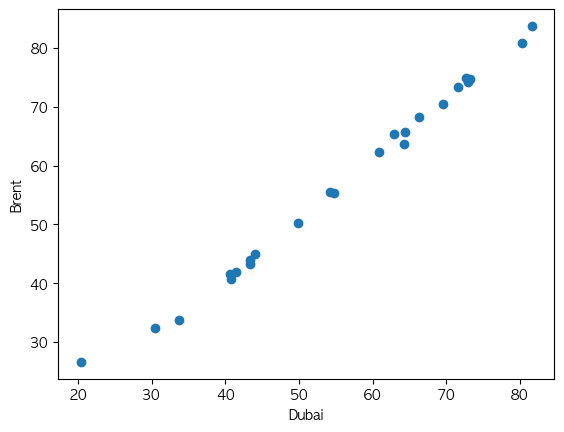

In [20]:
#세계 3대 석유종의 변화 추이가 비슷함을 나타낸 산점도
other = 'Brent' if BASE == 'Dubai' else 'WTI'
plt.scatter(oil[BASE], oil[other])
plt.xlabel(BASE); plt.ylabel(other)
plt.show()

In [21]:
#세계 3대 석유종의 변화 추이가 비슷함을 나타낸 상관계수 (1로 갈수록 선형도가 높음) -> 결국 3개 중 아무 데이터나 써도 괜찮음
oil['Brent'].corr(oil['WTI'])

0.9957336936063748

### 5-3. 델타항공 vs 엑슨모빌 월별 종가

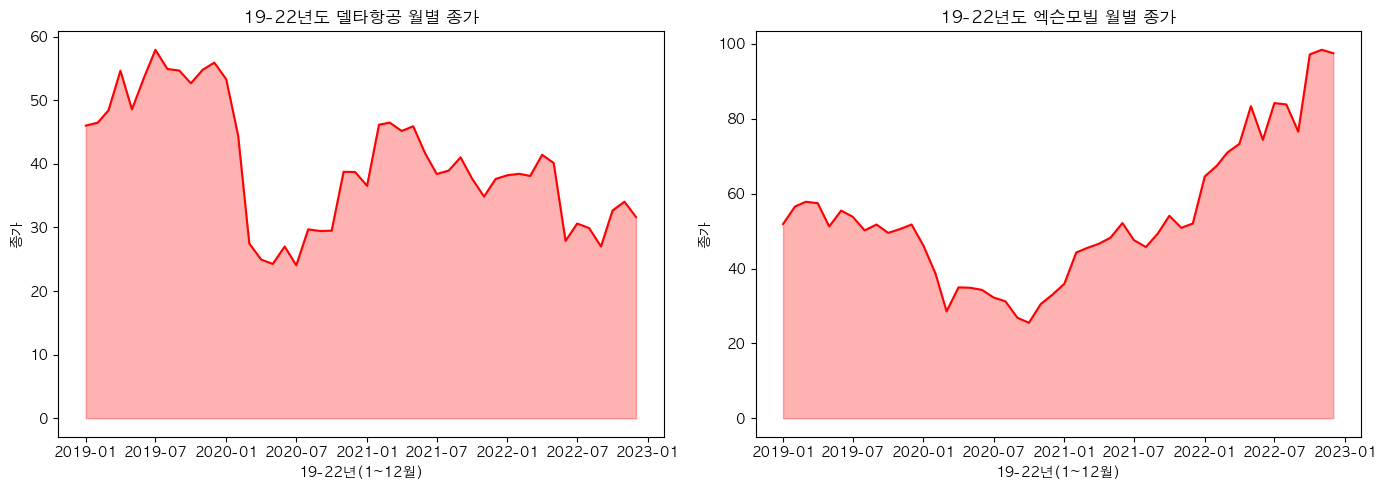

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
area_plot(axes[0], dal, '19-22년도 델타항공 월별 종가')
area_plot(axes[1], xom, '19-22년도 엑슨모빌 월별 종가')
plt.tight_layout()
plt.show()

### 5-4. 원유가격 변동과 원유사 주가 변동의 선형관계

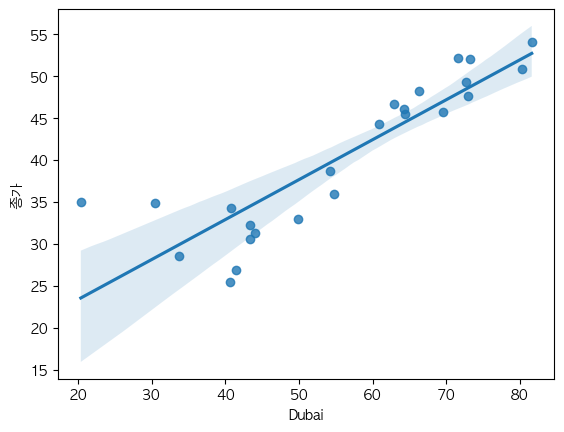

In [23]:
nxom = pd.DataFrame({'종가': xom.loc['2020':'2021']})
nxom = nxom.reindex(oil.index)      # 원유 데이터와 같은 월로 정렬

#세계 3대 유종 중 두바이와 엑슨모빌사의 종가의 선형도는 양의 선형관계를 가짐
sns.regplot(x=oil[BASE], y=nxom['종가'])
plt.show()

In [24]:
#상관계수가 0.7이 넘어감에 따라 양의 선형관계라는 주장을 뒷받침해줌
oil[BASE].corr(nxom['종가'])

0.8841195989728609

→ 원유의 가격변동에 따라 항공사와 원유사가 각각 주가에 변동을 받는다.

## 6. 결론 및 제언

| 관찰 | → | 결론 |
|---|---|---|
| 정치적, 자연재해적, 경제적, 정책적 요인 | → | **sell-in-may 전략 기각** |
| 주가 변동에 미치는 주요 요인 | → | **경제적 요인과 경제외적 요인** |

- sell-in-may는 계절성 하나만으로 매매 시점을 정하지만, 실제 주가와 거래량은 연도마다 다른 사건(선거, 재해, M&A, 감염병, 금리, 원자재 가격)에 더 크게 반응했다.
- 따라서 달력 기준의 일괄 매도보다, 경제적·경제외적 요인을 함께 살펴 판단하는 것이 바람직하다.